# Waste Classification Using Transfer Learning and Fine-Tuning

**Objective:** classify photographs of different waste types using a pretrained CNN, compare a frozen-base model with a fine-tuned model, and analyze its errors.

## 1. Installing and importing libraries



---



In [1]:
!pip -q install seaborn scikit-learn

import os
import zipfile
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix

# Make results more repeatable
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Uploading the Roboflow dataset

In [3]:
from google.colab import files

uploaded = files.upload()


Saving waste_dataset.zip.zip to waste_dataset.zip (1).zip


 ## 3. Extracting the dataset

In [4]:
zip_file = None

for file_name in uploaded.keys():
    if file_name.endswith(".zip"):
        zip_file = file_name
        break

if zip_file is None:
    raise ValueError("Please upload your dataset as a ZIP file.")

extract_path = "/content/roboflow_dataset"
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

# Display folders to help us locate the dataset
for folder in Path(extract_path).rglob("*"):
    if folder.is_dir() and len(folder.relative_to(extract_path).parts) <= 3:
        print(folder)

Dataset extracted successfully!
/content/roboflow_dataset/test
/content/roboflow_dataset/train
/content/roboflow_dataset/valid


## 4 Collecting all images and checking the requirements

In [7]:
import pathlib
import pandas as pd

# Define the raw dataset directory
RAW_DIR = "/content/roboflow_dataset"

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
ROBOFLOW_SPLITS = {"train", "valid", "val", "test"}


def collect_from_folders(root):
    # Folder-structure export: <root>/<split>/<class>/<image>
    rows = []
    for p in pathlib.Path(root).rglob("*"):
        if p.suffix.lower() in IMG_EXT and p.parent.parent.name.lower() in ROBOFLOW_SPLITS:
            rows.append((str(p), p.parent.name))
    return rows


def collect_from_csv(root):
    # Multiclass-CSV export: <root>/<split>/_classes.csv with one-hot class columns
    rows = []
    for csv_path in pathlib.Path(root).rglob("_classes.csv"):
        table = pd.read_csv(csv_path)
        table.columns = [c.strip() for c in table.columns]
        class_cols = [c for c in table.columns if c != "filename"]
        for _, r in table.iterrows():
            rows.append((str(csv_path.parent / r["filename"]), r[class_cols].astype(float).idxmax()))
    return rows


rows = collect_from_folders(RAW_DIR) or collect_from_csv(RAW_DIR)
assert rows, "No images found - check RAW_DIR and the export format."

df = pd.DataFrame(rows, columns=["filepath", "label"])
df["label"] = df["label"].str.strip()
df["group"] = df["label"] + "/" + df["filepath"].map(lambda p: os.path.basename(p).split(".rf.")[0])

counts = df["label"].value_counts()
print(f"Total images: {len(df)} | Unique source photos: {df['group'].nunique()} | Classes: {df['label'].nunique()}")
print(counts.to_string())
print("\nRequirement check")
print("  >= 5 classes     :", df["label"].nunique() >= 5)
print("  >= 200 per class :", bool((counts >= 200).all()))
print("  >= 1000 images   :", len(df) >= 1000)

Total images: 8195 | Unique source photos: 8195 | Classes: 10
label
paper          1050
biological      985
battery         945
cardboard       891
plastic         863
white-glass     775
metal           768
trash           697
green-glass     614
brown-glass     607

Requirement check
  >= 5 classes     : True
  >= 200 per class : True
  >= 1000 images   : True


## 5 Train / validation / test split (70 / 15 / 15)

In [15]:
import shutil

SPLIT_DIR = "/content/waste_split"
SEED = 42


def grouped_stratified_split(data, ratios=(0.70, 0.15, 0.15), seed=SEED):
    rng = np.random.default_rng(seed)
    split_of = {}
    for label, sub in data.groupby("label"):
        groups = sub["group"].unique()
        rng.shuffle(groups)
        n_train = int(round(ratios[0] * len(groups)))
        n_val = int(round(ratios[1] * len(groups)))
        for i, g in enumerate(groups):
            split_of[(label, g)] = "train" if i < n_train else ("val" if i < n_train + n_val else "test")
    return data.apply(lambda r: split_of[(r["label"], r["group"])], axis=1)


def materialise_split(data, out_dir):
    if os.path.exists(out_dir):
        shutil.rmtree(out_dir)
    for idx, r in data.iterrows():
        dst_dir = os.path.join(out_dir, r["split"], r["label"])
        os.makedirs(dst_dir, exist_ok=True)
        shutil.copy(r["filepath"], os.path.join(dst_dir, f"{idx}_{os.path.basename(r['filepath'])}"))


df["split"] = grouped_stratified_split(df)
materialise_split(df, SPLIT_DIR)

split_table = pd.crosstab(df["label"], df["split"])[["train", "val", "test"]]
split_table.loc["TOTAL"] = split_table.sum()
display(split_table)
print((df["split"].value_counts(normalize=True) * 100).round(1).to_string())

split,train,val,test
label,,,
battery,662,142,141
biological,690,148,147
brown-glass,425,91,91
cardboard,624,134,133
green-glass,430,92,92
metal,538,115,115
paper,735,158,157
plastic,604,129,130
trash,488,105,104


split
train    70.0
val      15.0
test     15.0


## 6 Exploratory visualisation — sample grid
A 5×5 grid of random training images with their class labels. This is a sanity check: are labels correct, how varied are backgrounds and lighting, and which classes look similar to each other?

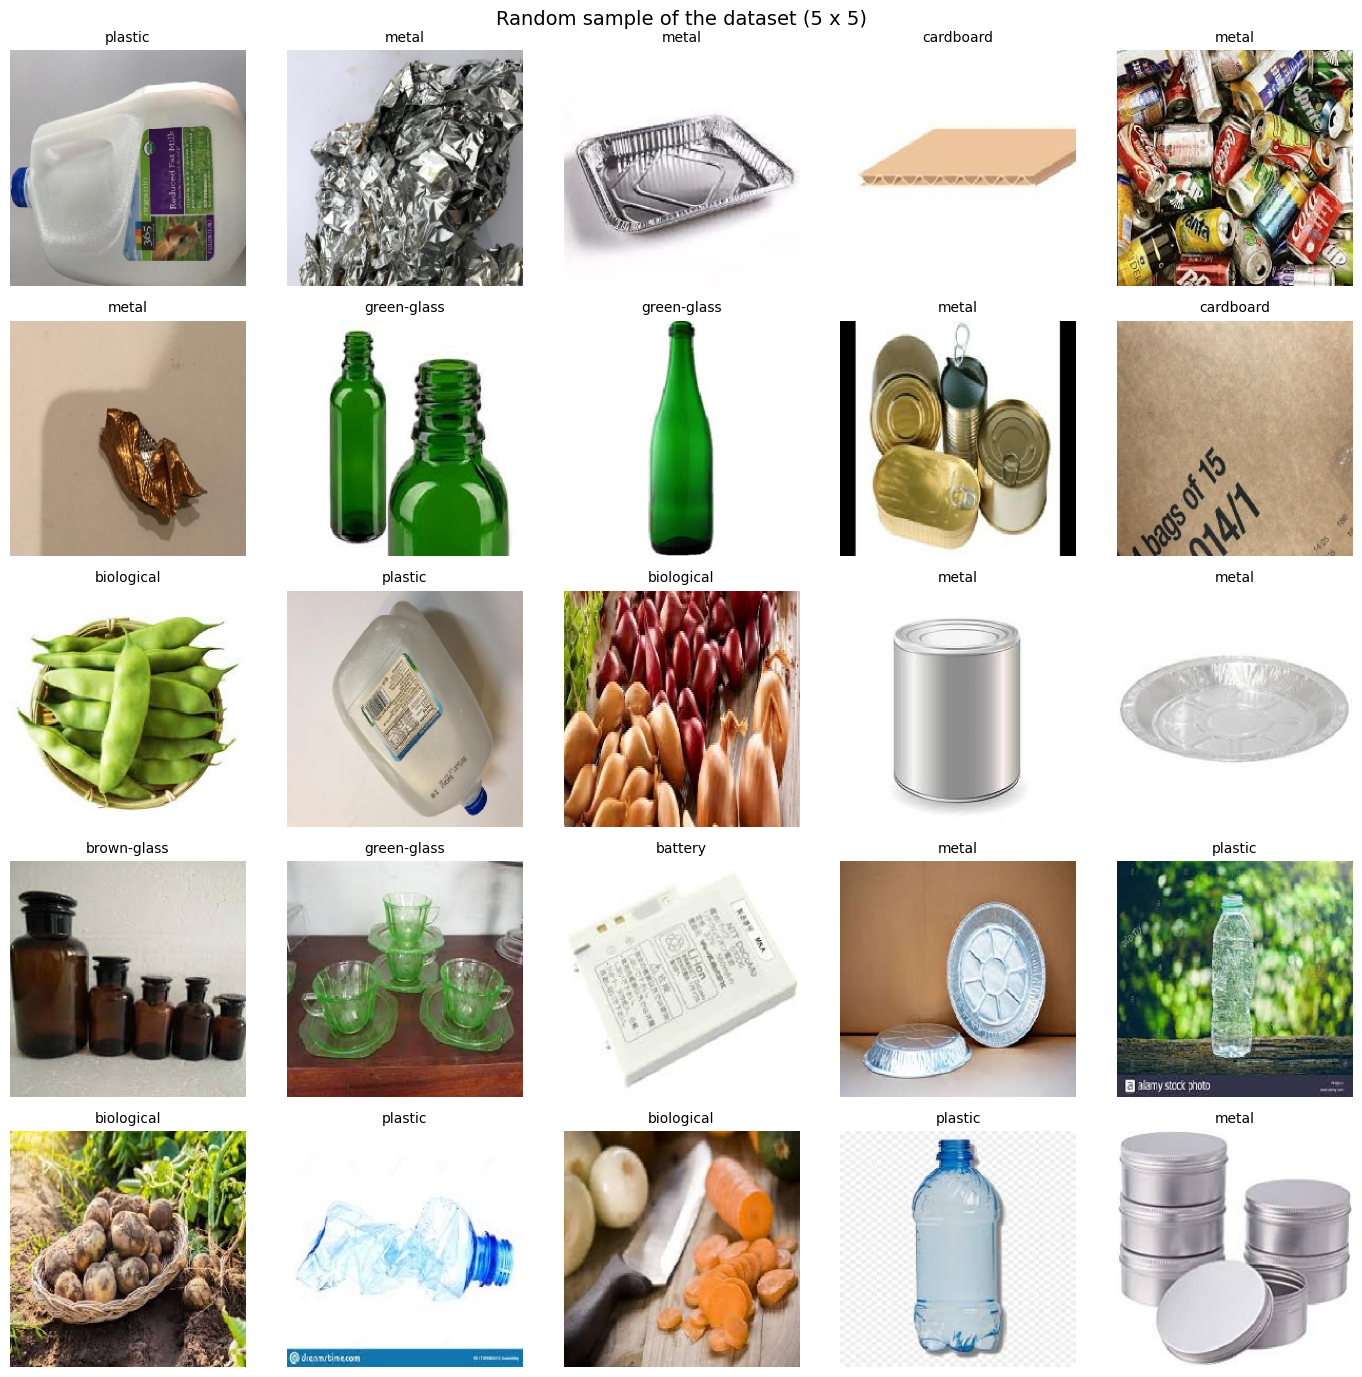

In [11]:
from tensorflow import keras

# Define standard image size for target resize
IMG_SIZE = (224, 224)

def show_sample_grid(data, n=5, seed=SEED):
    sample = data.sample(n * n, random_state=seed)
    fig, axes = plt.subplots(n, n, figsize=(14, 14))
    for ax, (_, r) in zip(axes.ravel(), sample.iterrows()):
        ax.imshow(keras.utils.load_img(r["filepath"], target_size=IMG_SIZE))
        ax.set_title(r["label"], fontsize=10)
        ax.axis("off")
    plt.suptitle("Random sample of the dataset (5 x 5)", fontsize=14)
    plt.tight_layout()
    plt.show()


show_sample_grid(df)

## 7 Class distribution and imbalance
The left plot shows the number of images per class, the right plot shows how each class is divided across the three splits. The imbalance ratio (largest class ÷ smallest class) tells me whether I need to compensate during training; I use balanced **class weights** in the loss, so under-represented classes are not ignored.

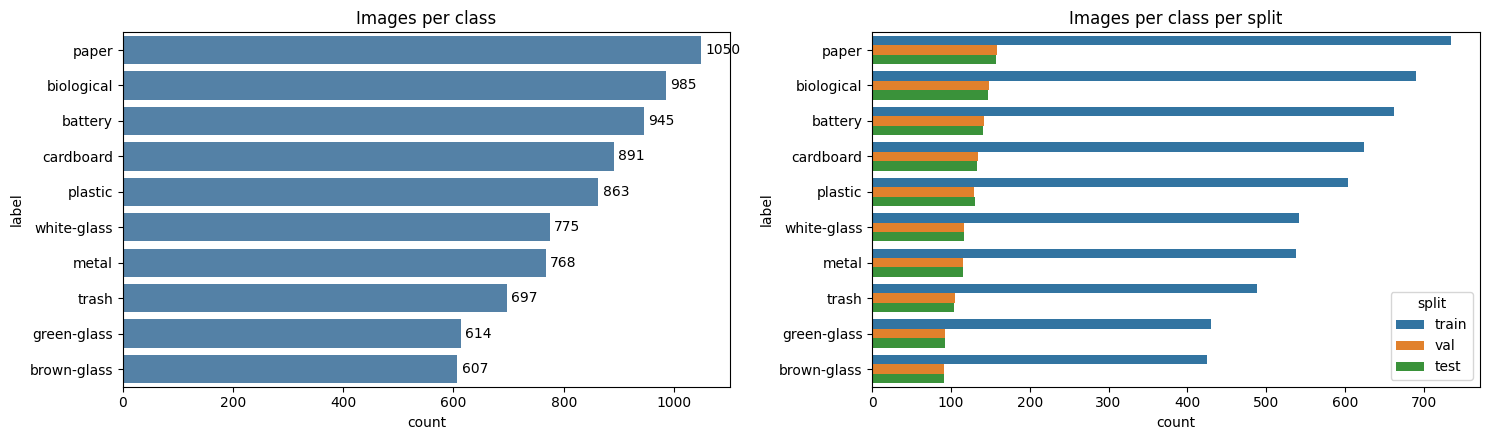

Imbalance ratio (largest / smallest class): 1.73
Largest: paper (1050) | Smallest: brown-glass (607)


In [12]:
def plot_class_distribution(data):
    order = data["label"].value_counts().index
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    sns.countplot(data=data, y="label", order=order, ax=axes[0], color="steelblue")
    for container in axes[0].containers:
        axes[0].bar_label(container, padding=3)
    axes[0].set_title("Images per class")
    sns.countplot(data=data, y="label", hue="split", order=order, hue_order=["train", "val", "test"], ax=axes[1])
    axes[1].set_title("Images per class per split")
    plt.tight_layout()
    plt.show()


plot_class_distribution(df)
class_counts = df["label"].value_counts()
print(f"Imbalance ratio (largest / smallest class): {class_counts.max() / class_counts.min():.2f}")
print(f"Largest: {class_counts.idxmax()} ({class_counts.max()}) | Smallest: {class_counts.idxmin()} ({class_counts.min()})")

**Discussion of the class distribution.** The dataset contains 8,195 images in 10 classes. It is mildly imbalanced: the largest class is paper (1,050 images) and the smallest is brown-glass (607), an imbalance ratio of 1.73. The right-hand plot shows that the stratified split keeps almost the same class proportions in train, validation and test (70 / 15 / 15). Because of the imbalance I use balanced class weights in the loss (about 0.78 for paper and 1.35 for brown-glass), and I judge the model with per-class precision / recall / F1 and macro-F1 rather than accuracy alone.

## 8 Data pipeline, normalisation and augmentation
**Loading:** `image_dataset_from_directory` reads the split folders, resizes every image to 224×224 and batches them. Only the *training* set is shuffled.

**Normalisation:** MobileNetV2 was pretrained on ImageNet with pixels scaled to **[−1, 1]**. I therefore add a `Rescaling(1/127.5, offset=-1)` layer inside the model (the exact equivalent of `mobilenet_v2.preprocess_input`), so every image — train, validation, test — is normalised the way the pretrained weights expect. (ResNet50/VGG16 would use mean/std subtraction instead; each Keras model family has its own `preprocess_input`.)

**Augmentation (training only)** — implemented as Keras layers that are active during training and automatically switched off at validation/test time:

| Technique | Why it suits waste photos |
|---|---|
| `RandomFlip` (horizontal + vertical) | A bottle or can has no "correct" orientation; items lie in any position in a bin or on a belt. |
| `RandomRotation` (±10% of a full turn ≈ ±36°) | Items are photographed at arbitrary angles. |
| `RandomZoom` (±15%) | Camera distance varies, so object size in the frame varies. |
| `RandomBrightness` (±20%) | Indoor/outdoor and day/night lighting differs between photos. |
| `RandomContrast` (±20%) | Different cameras and weather change contrast; helps with shiny materials (metal, glass). |

I deliberately avoid strong colour-hue changes, because colour carries information for some classes (e.g. brown cardboard, green glass).

In [31]:
from tensorflow.keras import layers
from sklearn.utils.class_weight import compute_class_weight

# Batch size and tf.data autotune setting
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def make_dataset(split, shuffle):
    return keras.utils.image_dataset_from_directory(
        os.path.join(SPLIT_DIR, split), image_size=IMG_SIZE, batch_size=BATCH_SIZE,
        label_mode="int", shuffle=shuffle, seed=SEED)


train_raw = make_dataset("train", shuffle=True)
val_raw = make_dataset("val", shuffle=False)
test_raw = make_dataset("test", shuffle=False)

class_names = train_raw.class_names
NUM_CLASSES = len(class_names)
test_files = list(test_raw.file_paths)       # kept for the error analysis in Part 4

train_ds = train_raw.prefetch(AUTOTUNE)
val_ds = val_raw.cache().prefetch(AUTOTUNE)
test_ds = test_raw.cache().prefetch(AUTOTUNE)

# Balanced class weights computed from the training split only
train_ids = [class_names.index(os.path.basename(os.path.dirname(p))) for p in train_raw.file_paths]
CLASS_WEIGHT = dict(enumerate(compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_ids)))

augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.15),
    layers.RandomBrightness(0.2),
    layers.RandomContrast(0.2),
], name="augmentation")

print("Classes:", class_names)
print("Class weights:", {class_names[k]: round(float(v), 2) for k, v in CLASS_WEIGHT.items()})

Found 5738 files belonging to 10 classes.
Found 1230 files belonging to 10 classes.
Found 1227 files belonging to 10 classes.
Classes: ['battery', 'biological', 'brown-glass', 'cardboard', 'green-glass', 'metal', 'paper', 'plastic', 'trash', 'white-glass']
Class weights: {'battery': 0.87, 'biological': 0.83, 'brown-glass': 1.35, 'cardboard': 0.92, 'green-glass': 1.33, 'metal': 1.07, 'paper': 0.78, 'plastic': 0.95, 'trash': 1.18, 'white-glass': 1.06}


## 9 Visual check of the augmentation
The first image is the original; the other seven are random augmentations of the same photo. They should look like plausible new photographs of the same object — if they do not, the augmentation is too aggressive.

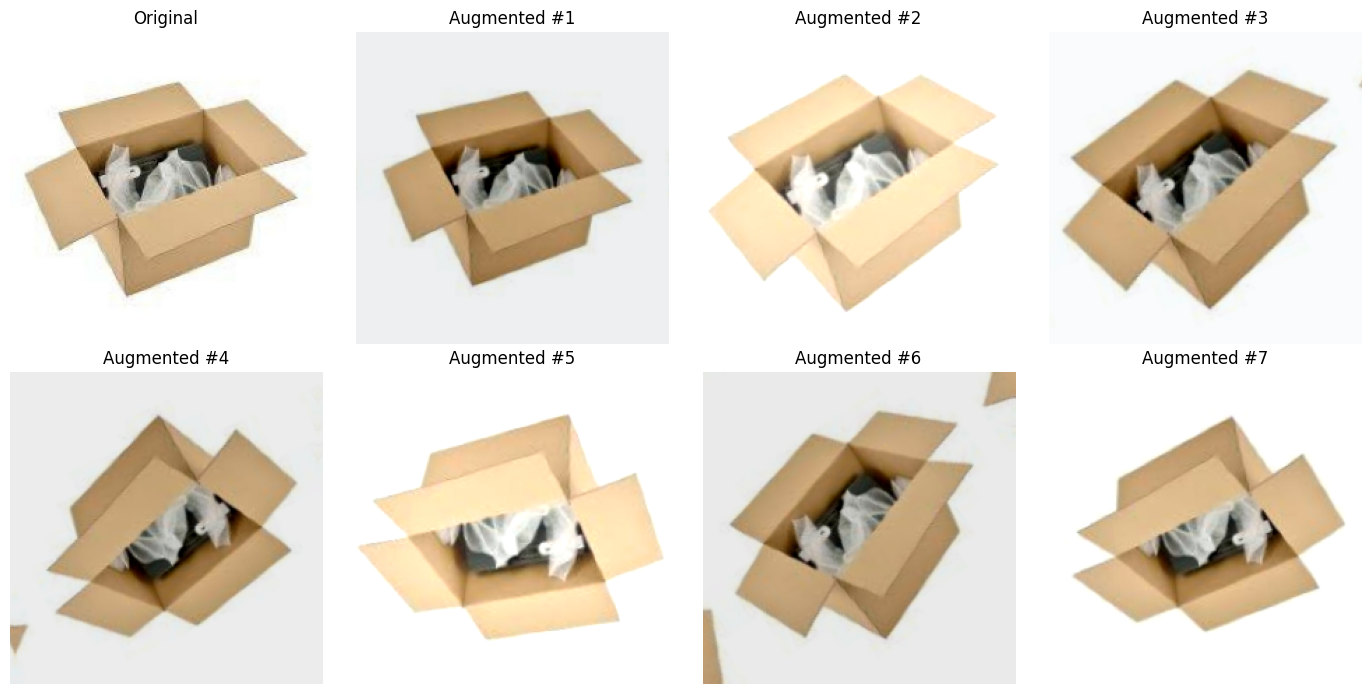

In [20]:
def show_augmentations():
    images, _ = next(iter(train_raw.take(1)))
    original = images[:1]
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for i, ax in enumerate(axes.ravel()):
        img = original if i == 0 else augmentation(original, training=True)
        ax.imshow(np.clip(img[0].numpy(), 0, 255).astype("uint8"))
        ax.set_title("Original" if i == 0 else f"Augmented #{i}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()


show_augmentations()

# Part 2 — Transfer Learning (Frozen Base)

## 2.1 Choice of pretrained architecture: MobileNetV2
| Model | Total params (with top) | Size on disk | ImageNet top-1 | Typical use |
|---|---|---|---|---|
| VGG16 | ~138 M | ~528 MB | ~71% | Heavy, slow, memory hungry |
| ResNet50 | ~25.6 M | ~98 MB | ~75% | Strong, general-purpose |
| EfficientNetB0 | ~5.3 M | ~29 MB | ~77% | Accurate and small, but sensitive to its own preprocessing |
| **MobileNetV2** | **~3.5 M** | **~14 MB** | **~71%** | **Very light and fast, designed for mobile / edge devices** |

*(Figures are the approximate values from the Keras Applications documentation.)*

**Justification.**
1. **Dataset size:** my dataset has a few thousand images. A small network (≈2.2 M parameters in the base without the top) has far less capacity to overfit than ResNet50 (≈23.5 M) or VGG16 (≈14.7 M conv-base).
2. **Real-world deployment:** waste sorting is typically run on embedded hardware (smart bins, conveyor cameras, phones). MobileNetV2 uses depthwise-separable convolutions and gives fast inference at small memory cost.
3. **Experiment speed:** quicker epochs on Colab's free GPU means I can run both the frozen and fine-tuning phases comfortably.
4. **Trade-off:** I accept a slightly lower ImageNet accuracy than EfficientNetB0/ResNet50 in exchange for speed and size.

## 2.2 Building the model
The model is assembled in this order:

`Input → Augmentation → Rescaling to [-1,1] → MobileNetV2 base (frozen) → GlobalAveragePooling2D → Dropout(0.3) → Dense(256, ReLU) → Dropout(0.4) → Dense(softmax)`

**Why this head?**
- `GlobalAveragePooling2D` turns the 7×7×1280 feature map into a 1280-vector with **zero** parameters (a `Flatten` + Dense would add ~12 M parameters and overfit).
- `Dense(256, ReLU)` is a small trainable layer that re-combines the generic ImageNet features for waste-specific classes.
- **Dropout** (0.3 before and 0.4 after the dense layer) randomly silences units during training to reduce overfitting on a small dataset.
- `softmax` outputs a probability for each class.

The base is called with `training=False` so its BatchNorm layers stay in inference mode (they keep ImageNet's running statistics), which matters especially later during fine-tuning.

In [21]:
def build_model(num_classes, dense_units=256):
    base = keras.applications.MobileNetV2(
        input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet", name="mobilenetv2_base")
    base.trainable = False                                   # freeze every layer of the base

    inputs = keras.Input(shape=IMG_SIZE + (3,), name="image")
    x = augmentation(inputs)
    x = layers.Rescaling(1.0 / 127.5, offset=-1, name="mobilenet_preprocess")(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(dense_units, activation="relu", name="dense_head")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)
    return keras.Model(inputs, outputs, name="waste_classifier"), base


def count_params(model):
    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    non_trainable = int(sum(np.prod(w.shape) for w in model.non_trainable_weights))
    return trainable, non_trainable


model, base_model = build_model(NUM_CLASSES)
trainable, non_trainable = count_params(model)
print(f"Base model layers      : {len(base_model.layers)}")
print(f"Trainable parameters   : {trainable:,}")
print(f"Non-trainable (frozen) : {non_trainable:,}")
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Base model layers      : 154
Trainable parameters   : 330,506
Non-trainable (frozen) : 2,257,984


Model: "waste_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocess            │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_base (Functional)   │ (None, 7, 7, 1280)     │     2,257,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_head (Dense)              │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,588,490 (9.87 MB)

 Trainable params: 330,506 (1.26 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 2.3 Training the frozen-base model
Only the new classification head is trained; the pretrained convolutional layers act as a fixed feature extractor.

- **Optimizer:** Adam, learning rate `1e-3` (a standard choice when training randomly-initialised layers).
- **Loss:** sparse categorical cross-entropy (labels are integers).
- **Epochs:** 25
- **Class weights:** balanced, to counter class imbalance.
- **Checkpoint:** the weights of the epoch with the best *validation accuracy* are saved to disk. The test set plays no part in this choice.

In [22]:
def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])


EPOCHS_FROZEN = 25
INITIAL_LR = 1e-3

compile_model(model, INITIAL_LR)
checkpoint_frozen = keras.callbacks.ModelCheckpoint(
    "best_frozen.weights.h5", monitor="val_accuracy", mode="max",
    save_best_only=True, save_weights_only=True)

history_frozen = model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS_FROZEN,
    class_weight=CLASS_WEIGHT, callbacks=[checkpoint_frozen])

Epoch 1/25
180/180 ━━━━━━━━━━━━━━━━━━━━ 27s 99ms/step - accuracy: 0.6919 - loss: 0.9519 - val_accuracy: 0.8659 - val_loss: 0.4108
Epoch 2/25
180/180 ━━━━━━━━━━━━━━━━━━━━ 14s 78ms/step - accuracy: 0.8174 - loss: 0.5681 - val_accuracy: 0.8780 - val_loss: 0.3651
Epoch 3/25
180/180 ━━━━━━━━━━━━━━━━━━━━ 21s 83ms/step - accuracy: 0.8353 - loss: 0.4915 - val_accuracy: 0.8829 - val_loss: 0.3524
Epoch 4/25
180/180 ━━━━━━━━━━━━━━━━━━━━ 20s 79ms/step - accuracy: 0.8515 - loss: 0.4372 - val_accuracy: 0.8943 - val_loss: 0.3105
Epoch 5/25
180/180 ━━━━━━━━━━━━━━━━━━━━ 15s 85ms/step - accuracy: 0.8557 - loss: 0.4258 - val_accuracy: 0.8919 - val_loss: 0.3007
Epoch 6/25
180/180 ━━━━━━━━━━━━━━━━━━━━ 15s 84ms/step - accuracy: 0.8695 - loss: 0.3909 - val_accuracy: 0.8992 - val_loss: 0.2908
Epoch 7/25
180/180 ━━━━━━━━━━━━━━━━━━━━ 22s 92ms/step - accuracy: 0.8750 - loss: 0.3780 - val_accuracy: 0.8935 - val_loss: 0.3078
Epoch 8/25
180/180 ━━━━━━━━━━━━━━━━━━━━ 19s 86ms/step - accuracy: 0.8764 - loss: 0.3562 - 

## 2.4 Training curves and recording the frozen-base baseline
I plot training vs. validation accuracy and loss, then restore the best checkpoint and record the baseline metrics (validation accuracy/loss, test accuracy, trainable parameters) that I will compare against fine-tuning in Part 3.

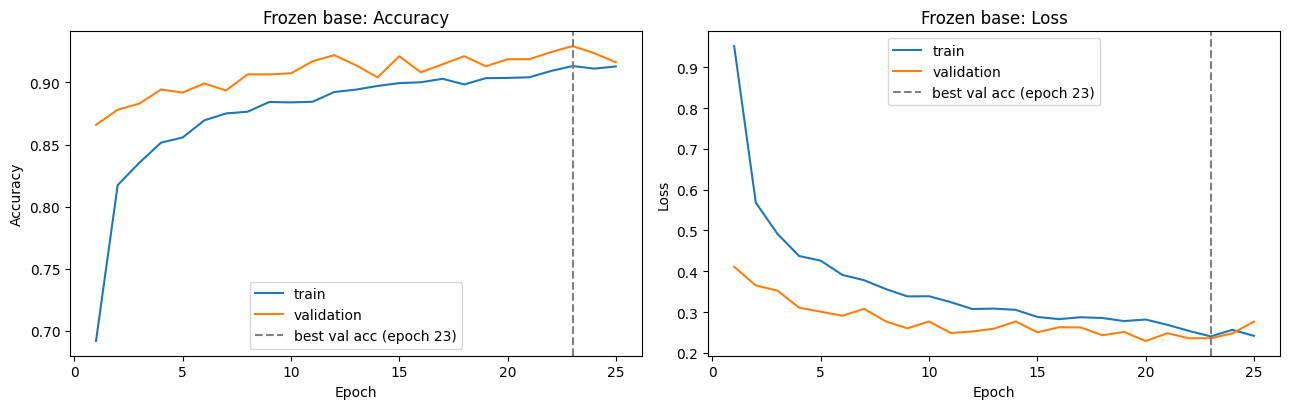

Best frozen-base validation accuracy : 0.9293
Validation loss at that checkpoint   : 0.2356
Test accuracy (frozen base)          : 0.9209


In [23]:
def plot_history(history, title):
    h = history.history
    epochs = range(1, len(h["accuracy"]) + 1)
    best = int(np.argmax(h["val_accuracy"])) + 1
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    for ax, key, name in zip(axes, ["accuracy", "loss"], ["Accuracy", "Loss"]):
        ax.plot(epochs, h[key], label="train")
        ax.plot(epochs, h["val_" + key], label="validation")
        ax.axvline(best, color="grey", linestyle="--", label=f"best val acc (epoch {best})")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(name)
        ax.set_title(f"{title}: {name}")
        ax.legend()
    plt.tight_layout()
    plt.show()


plot_history(history_frozen, "Frozen base")

model.load_weights("best_frozen.weights.h5")
frozen_val_loss, frozen_val_acc = model.evaluate(val_ds, verbose=0)
_, frozen_test_acc = model.evaluate(test_ds, verbose=0)
frozen_trainable, _ = count_params(model)
print(f"Best frozen-base validation accuracy : {frozen_val_acc:.4f}")
print(f"Validation loss at that checkpoint   : {frozen_val_loss:.4f}")
print(f"Test accuracy (frozen base)          : {frozen_test_acc:.4f}")

Comments the frozen-base curves


• Convergence: validation accuracy was already 86.6% after epoch 1, reached about 89% by epoch 5, and then kept improving slowly and noisily to its best value of 92.93% at epoch 23. The head has largely converged, although the training curve was still rising slightly at epoch 25.

• Over/underfitting: the gap between training and validation accuracy is small (with validation surprisingly outperforming training across most epochs due to regularization like dropout/augmentation during training).

• Why the plateau: with a frozen base the model can only re-weight ImageNet features; it cannot adapt the convolutional filters to waste-specific textures. This ceiling is what fine-tuning should lift.

• Best frozen-base validation accuracy: 0.9293 (or 92.93%) — this is the baseline for Part 3.

# Part 3 — Fine-Tuning

## 3.1 Unfreezing strategy
**What I unfreeze:** the last **30 layers** of MobileNetV2 (it has 154 layers; 30 ≈ the final two inverted-residual blocks plus the last 1×1 convolution).

**Why only the top layers?**
- Early layers detect generic edges, colours and textures that transfer to any image domain — there is no need to change them.
- Deeper layers encode increasingly task-specific, high-level patterns. These benefit most from adapting to waste materials.
- Unfreezing everything on a small dataset would cause overfitting and could destroy useful pretrained features ("catastrophic forgetting").

**BatchNorm layers stay frozen.** Even inside the unfrozen block, I keep `BatchNormalization` layers non-trainable. With small batches and a small dataset, updating BN statistics can destabilise training and degrade accuracy.

**Learning rate: `5e-5`** — 20× smaller than the initial `1e-3` (inside the recommended 10×–100× range). Pretrained weights are already close to a good solution; large updates would overwrite them. A small LR makes gentle, stable adjustments.

**LR schedule: `ReduceLROnPlateau`** — monitors validation loss and multiplies the LR by 0.3 whenever it has not improved for 2 epochs (down to a floor of `1e-7`). This lets the model take fine steps once progress stalls.

**Continuing, not restarting:** the best frozen-base weights are already loaded in `model` (Part 2.4), so training simply continues from that checkpoint. Changing `trainable` requires re-compiling the model, which resets only the optimizer state, not the weights.

In [24]:
UNFREEZE_LAST_N = 30
FINE_TUNE_LR = 5e-5


def unfreeze_top_layers(base, n):
    base.trainable = True
    for layer in base.layers[:-n]:
        layer.trainable = False
    for layer in base.layers[-n:]:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False


frozen_params = count_params(model)
unfreeze_top_layers(base_model, UNFREEZE_LAST_N)
compile_model(model, FINE_TUNE_LR)
tuned_params = count_params(model)

trainable_layers = sum(layer.trainable for layer in base_model.layers)
print(f"Trainable base layers (non-BN, top {UNFREEZE_LAST_N}): {trainable_layers} of {len(base_model.layers)}")
print(f"{'':22s}{'Trainable':>14s}{'Non-trainable':>16s}")
print(f"{'Before (frozen)':22s}{frozen_params[0]:>14,}{frozen_params[1]:>16,}")
print(f"{'After (fine-tuning)':22s}{tuned_params[0]:>14,}{tuned_params[1]:>16,}")

Trainable base layers (non-BN, top 30): 19 of 154
                           Trainable   Non-trainable
Before (frozen)              330,506       2,257,984
After (fine-tuning)        1,841,226         747,264


## 3.2 Fine-tuning run
Training continues for up to 20 more epochs with:
- `ReduceLROnPlateau` (the LR schedule),
- `LRLogger` (a small custom callback that records the learning rate used in each epoch, so the schedule can be plotted),
- `ModelCheckpoint` keeping the weights with the best validation accuracy.

The same class weights are used as before.

In [25]:
class LRLogger(keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.lrs = []

    def on_epoch_begin(self, epoch, logs=None):
        self.lrs.append(float(np.array(self.model.optimizer.learning_rate)))


EPOCHS_FINE = 20
lr_logger = LRLogger()
callbacks_fine = [
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7, verbose=1),
    keras.callbacks.ModelCheckpoint("best_finetuned.weights.h5", monitor="val_accuracy", mode="max",
                                    save_best_only=True, save_weights_only=True),
    lr_logger,
]

history_fine = model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS_FINE,
    class_weight=CLASS_WEIGHT, callbacks=callbacks_fine)

Epoch 1/20


/tmp/ipykernel_2377/3109332209.py:7: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  self.lrs.append(float(np.array(self.model.optimizer.learning_rate)))


180/180 ━━━━━━━━━━━━━━━━━━━━ 25s 95ms/step - accuracy: 0.9041 - loss: 0.2781 - val_accuracy: 0.9089 - val_loss: 0.2807 - learning_rate: 5.0000e-05
Epoch 2/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 19s 103ms/step - accuracy: 0.9085 - loss: 0.2549 - val_accuracy: 0.9195 - val_loss: 0.2388 - learning_rate: 5.0000e-05
Epoch 3/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 19s 103ms/step - accuracy: 0.9165 - loss: 0.2313 - val_accuracy: 0.9203 - val_loss: 0.2634 - learning_rate: 5.0000e-05
Epoch 4/20
179/180 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9220 - loss: 0.2257
Epoch 4: ReduceLROnPlateau reducing learning rate to 1.4999999621068127e-05.
180/180 ━━━━━━━━━━━━━━━━━━━━ 16s 91ms/step - accuracy: 0.9221 - loss: 0.2250 - val_accuracy: 0.9163 - val_loss: 0.2722 - learning_rate: 5.0000e-05
Epoch 5/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 20s 86ms/step - accuracy: 0.9467 - loss: 0.1515 - val_accuracy: 0.9341 - val_loss: 0.2123 - learning_rate: 1.5000e-05
Epoch 6/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 20s 84ms/step - accuracy: 

### Fine-tuning curves and the learning-rate schedule
First, the training / validation curves of the fine-tuning phase on their own. Second, the learning rate per epoch — drops in this curve show when `ReduceLROnPlateau` fired.

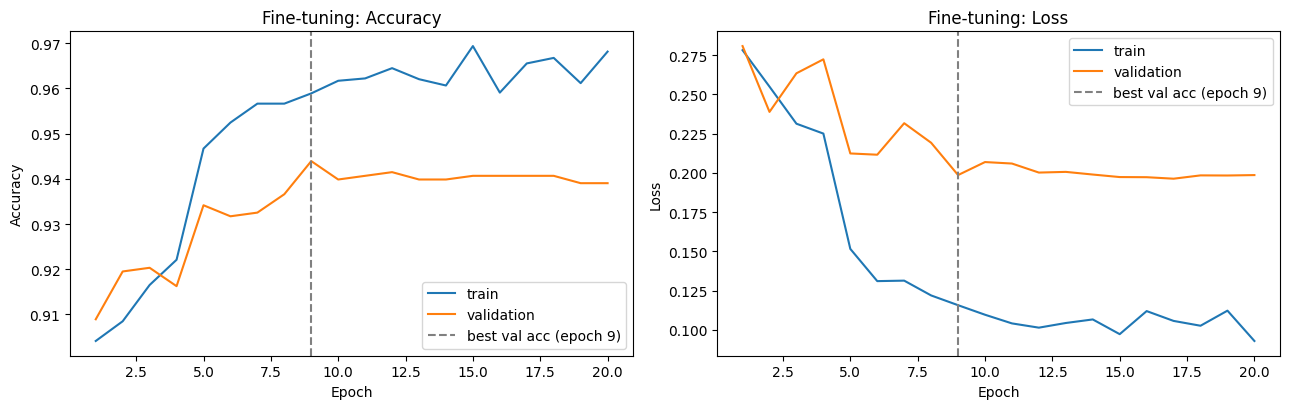

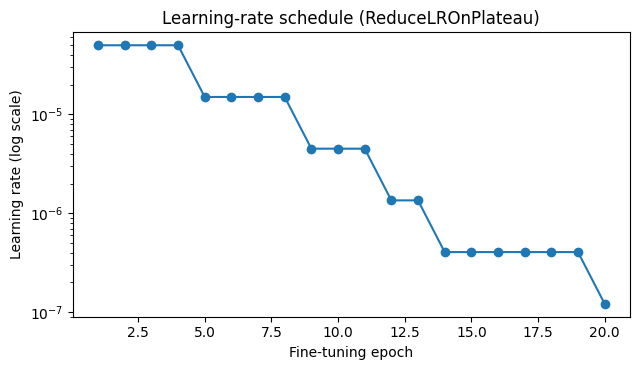

Logged learning rates: ['5.0e-05', '5.0e-05', '5.0e-05', '5.0e-05', '1.5e-05', '1.5e-05', '1.5e-05', '1.5e-05', '4.5e-06', '4.5e-06', '4.5e-06', '1.3e-06', '1.3e-06', '4.0e-07', '4.0e-07', '4.0e-07', '4.0e-07', '4.0e-07', '4.0e-07', '1.2e-07']


In [26]:
def plot_lr(lrs):
    plt.figure(figsize=(6.5, 3.8))
    plt.plot(range(1, len(lrs) + 1), lrs, marker="o")
    plt.yscale("log")
    plt.xlabel("Fine-tuning epoch")
    plt.ylabel("Learning rate (log scale)")
    plt.title("Learning-rate schedule (ReduceLROnPlateau)")
    plt.tight_layout()
    plt.show()


plot_history(history_fine, "Fine-tuning")
plot_lr(lr_logger.lrs)
print("Logged learning rates:", [f"{lr:.1e}" for lr in lr_logger.lrs])

Comments on fine-tuning stability

Training was slightly noisy during fine-tuning. The learning rate was reduced 5 times (the new rate first applied at epochs 5, 9, 12, 14 and 20, ending at about 1.2e-7), after validation loss stopped improving. Validation accuracy moved from 92.93% to 94.39% (best val acc at epoch 9). The gap between training and validation accuracy is larger than in the frozen phase, which indicates mild overfitting. After epoch 9 the training accuracy kept rising (to about 97%) while the validation accuracy stayed at about 94%, so the later epochs added little.

## 3.3 Before / after comparison
The best fine-tuned checkpoint (selected on **validation** accuracy) is restored, and all four required metrics are put side-by-side with the frozen-base baseline.

In [27]:
model.load_weights("best_finetuned.weights.h5")
ft_val_loss, ft_val_acc = model.evaluate(val_ds, verbose=0)
_, ft_test_acc = model.evaluate(test_ds, verbose=0)
ft_trainable, _ = count_params(model)

comparison = pd.DataFrame({
    "Metric": ["Validation Accuracy", "Validation Loss", "Test Accuracy", "Trainable Params"],
    "Frozen Base": [f"{frozen_val_acc:.4f}", f"{frozen_val_loss:.4f}", f"{frozen_test_acc:.4f}", f"{frozen_trainable:,}"],
    "After Fine-Tuning": [f"{ft_val_acc:.4f}", f"{ft_val_loss:.4f}", f"{ft_test_acc:.4f}", f"{ft_trainable:,}"],
}).set_index("Metric")
display(comparison)

print(f"Validation accuracy change: {100 * (ft_val_acc - frozen_val_acc):+.2f} percentage points")
print(f"Test accuracy change      : {100 * (ft_test_acc - frozen_test_acc):+.2f} percentage points")

,Frozen Base,After Fine-Tuning
Metric,,
Validation Accuracy,0.9293,0.9439
Validation Loss,0.2356,0.1985
Test Accuracy,0.9209,0.9405
Trainable Params,"330,506","1,841,226"


Validation accuracy change: +1.46 percentage points
Test accuracy change      : +1.96 percentage points


# Part 4 — Evaluation & Analysis

## 4.1 Classification report
Predictions of the fine-tuned model on the **test set** are collected once and reused by all evaluation cells below. The classification report gives **precision** (of the items predicted as class X, how many really were X), **recall** (of the real X items, how many were found) and **F1** (their harmonic mean) per class. The two classes with the lowest F1 are flagged automatically.

In [28]:
def get_predictions(model, ds):
    y_true = np.concatenate([y.numpy() for _, y in ds])
    probs = model.predict(ds, verbose=0)
    return y_true, probs.argmax(axis=1), probs


y_true, y_pred, probs = get_predictions(model, test_ds)

report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
report_df = pd.DataFrame(report).T
per_class = report_df.loc[class_names, ["precision", "recall", "f1-score", "support"]]
display(per_class.round(3).style.background_gradient(subset=["f1-score"], cmap="RdYlGn"))

print(f"Overall test accuracy: {report['accuracy']:.4f} | Macro F1: {report['macro avg']['f1-score']:.4f}")
hardest = per_class["f1-score"].nsmallest(2)
print("\nTwo hardest classes (lowest F1):")
for name, f1 in hardest.items():
    print(f"  {name}: F1 = {f1:.3f} (precision {per_class.loc[name, 'precision']:.3f}, recall {per_class.loc[name, 'recall']:.3f})")

,precision,recall,f1-score,support
battery,0.985000,0.950000,0.968000,141.000000
biological,0.980000,1.000000,0.990000,147.000000
brown-glass,0.977000,0.934000,0.955000,91.000000
cardboard,0.949000,0.970000,0.959000,133.000000
green-glass,0.937000,0.967000,0.952000,92.000000
metal,0.837000,0.939000,0.885000,115.000000
paper,0.954000,0.924000,0.939000,157.000000
plastic,0.891000,0.885000,0.888000,130.000000
trash,1.000000,0.971000,0.985000,104.000000
white-glass,0.902000,0.863000,0.882000,117.000000


Overall test accuracy: 0.9405 | Macro F1: 0.9403

Two hardest classes (lowest F1):
  white-glass: F1 = 0.882 (precision 0.902, recall 0.863)
  metal: F1 = 0.885 (precision 0.837, recall 0.939)


**The two hardest classes — hypotheses**

The hardest classes were **white-glass** (F1 = 0.882) and **metal** (F1 = 0.885), followed closely by plastic (F1 = 0.888). My hypotheses:

- **Visual similarity (white-glass):** clear glass and clear plastic bottles are both transparent, glossy and similarly shaped. White-glass was predicted as plastic in 8 test images and plastic as white-glass in 6. In the error images these are transparent bottles on plain backgrounds, where only subtle cues (thickness, rim, neck) separate the two materials.
- **Metal works as a "catch-all" prediction (low precision):** metal has high recall (0.939) but low precision (0.837). Only 7 true metal images were missed, but 21 images from six other classes were predicted as metal (white-glass 6, battery 4, plastic 4, brown-glass 3, paper 3, cardboard 1). Shiny, dark or reflective objects such as battery casings, bottle caps and glass glare seem to share features with metal.
- **Within-class variety:** metal covers cans, foil and tins with very different shapes, so its decision region is broad and can "absorb" ambiguous reflective items.
- **Photo quality and label noise:** the error analysis shows reflections, cluttered piles of objects and a few questionable labels.
- **Not a sample-size problem:** white-glass has 542 training images, in the middle of the range; the smaller classes (brown-glass 425, green-glass 430) perform well.

## 4.2 Confusion matrix
The heatmap shows, for each true class (rows), how its test images were predicted (columns). The diagonal is correct predictions; off-diagonal cells are mistakes. I plot raw counts and the row-normalised version (percentage of each true class), which makes classes of different sizes comparable. The most frequent misclassification pair is computed automatically.

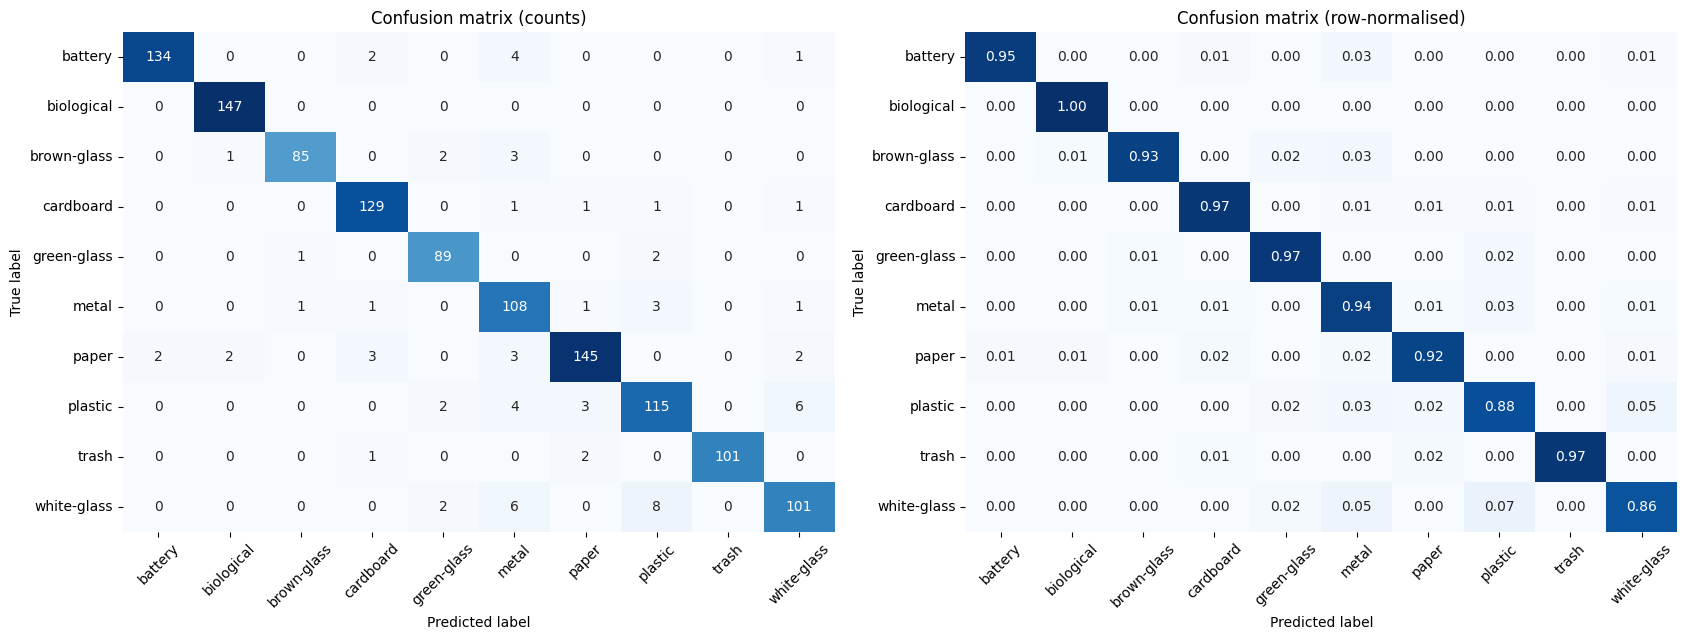

Most common misclassification: true 'white-glass' predicted as 'plastic' (8 images)


In [29]:
def plot_confusion(cm, names, normalize, ax):
    data = cm / cm.sum(axis=1, keepdims=True) if normalize else cm
    sns.heatmap(data, annot=True, fmt=".2f" if normalize else "d", cmap="Blues",
                xticklabels=names, yticklabels=names, cbar=False, ax=ax)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_title("Confusion matrix (row-normalised)" if normalize else "Confusion matrix (counts)")
    ax.tick_params(axis="x", rotation=45)


cm = confusion_matrix(y_true, y_pred)
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
plot_confusion(cm, class_names, normalize=False, ax=axes[0])
plot_confusion(cm, class_names, normalize=True, ax=axes[1])
plt.tight_layout()
plt.show()

off_diag = cm.copy()
np.fill_diagonal(off_diag, 0)
i, j = np.unravel_index(off_diag.argmax(), off_diag.shape)
print(f"Most common misclassification: true '{class_names[i]}' predicted as '{class_names[j]}' ({off_diag[i, j]} images)")

**Reading the confusion matrix**

The most common confusion is white-glass → plastic (8 images). This matches the hardest-class analysis: clear glass and clear plastic share transparency, gloss and bottle shapes. The confusion is nearly symmetric, not one-directional: plastic → white-glass happens 6 times, so the two classes simply overlap visually, and 8 vs 6 is too small a difference to claim a bias towards "plastic". The clearer pattern is the **metal column**: 21 images from six other classes were predicted as metal, so the model leans towards "metal" for shiny or dark objects. All other classes are recognised reliably, with row-normalised diagonal values of 0.92–1.00 (biological 1.00, cardboard / green-glass / trash 0.97, battery 0.95, metal 0.94, brown-glass 0.93, paper 0.92). The weakest diagonal values are plastic (0.88) and white-glass (0.86).

## 4.3 Error analysis
Twelve randomly chosen misclassified test images are shown with their true label, predicted label and the model's confidence. A table of the most frequent (true → predicted) error pairs follows. The aim is to decide whether errors are **systematic** (the same classes confused repeatedly, or recurring image conditions) or **random**.

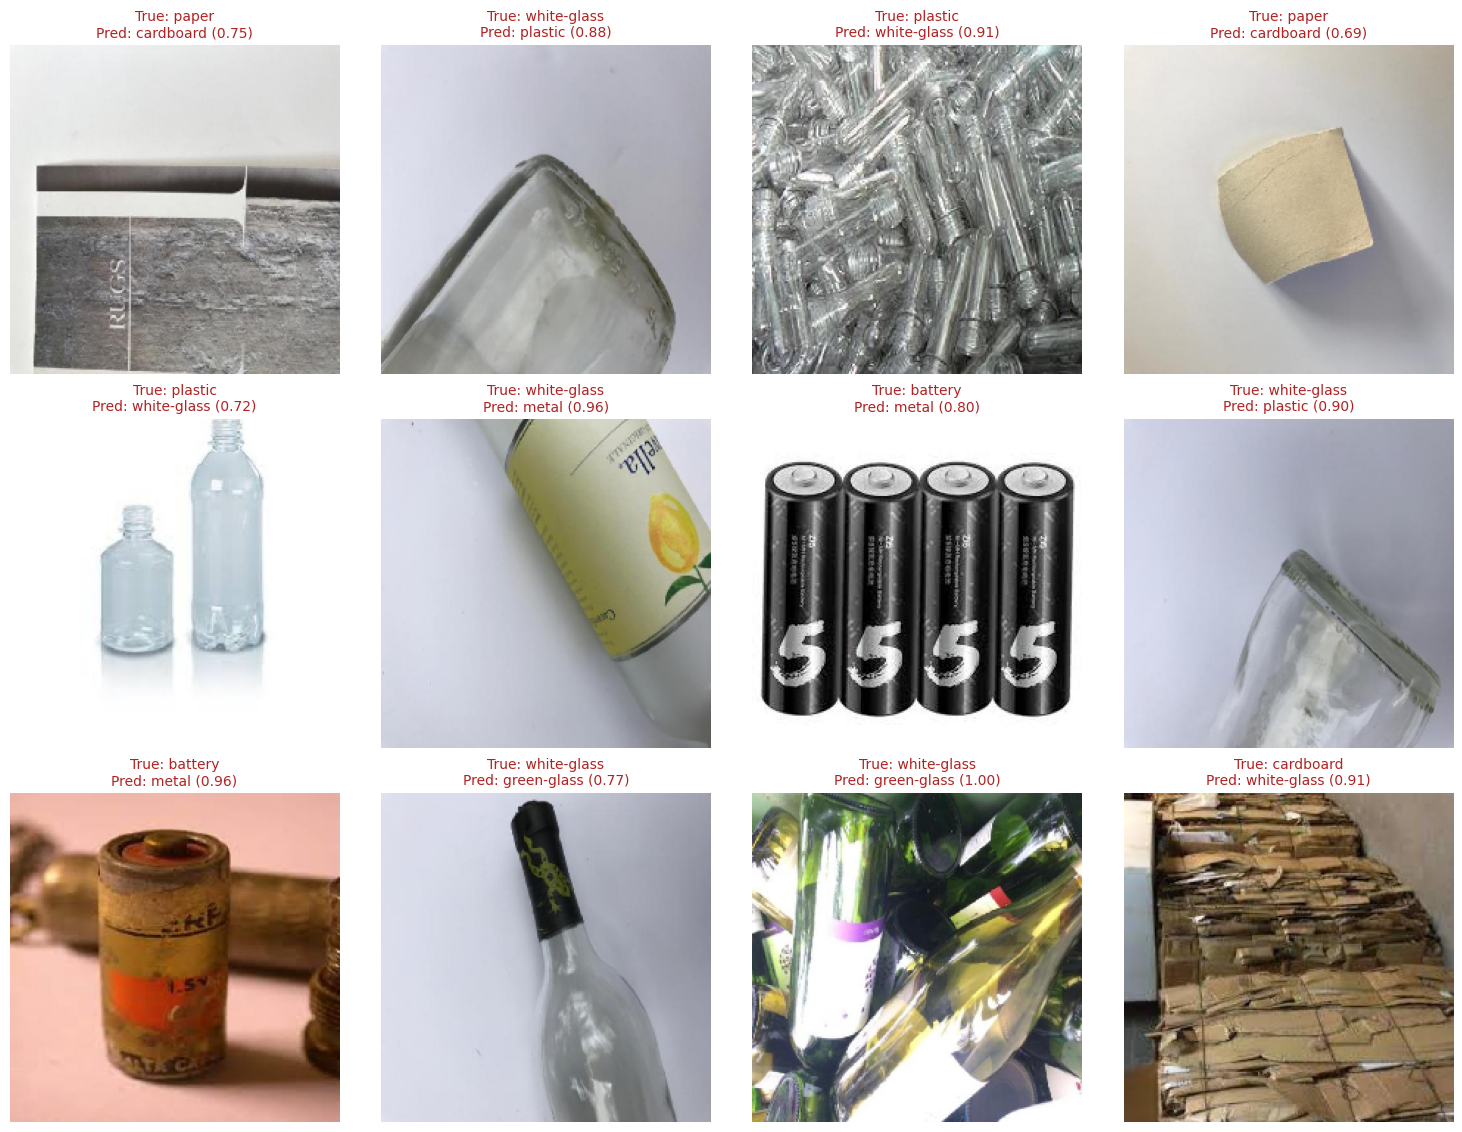

Misclassified test images: 73 of 1227 (5.9%)


,True,Predicted,Count
0,white-glass,plastic,8
1,plastic,white-glass,6
2,white-glass,metal,6
3,battery,metal,4
4,plastic,metal,4
5,brown-glass,metal,3
6,metal,plastic,3
7,paper,metal,3


In [32]:
from collections import Counter

def show_misclassified(files, y_true, y_pred, probs, n=12, seed=SEED):
    wrong = np.where(y_true != y_pred)[0]
    chosen = np.random.default_rng(seed).choice(wrong, size=min(n, len(wrong)), replace=False)
    cols = 4
    rows = int(np.ceil(len(chosen) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(15, 3.8 * rows))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for ax, idx in zip(np.atleast_1d(axes).ravel(), chosen):
        ax.imshow(keras.utils.load_img(files[idx], target_size=IMG_SIZE))
        ax.set_title(f"True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]} ({probs[idx].max():.2f})",
                     fontsize=10, color="firebrick")
    plt.tight_layout()
    plt.show()
    return wrong


wrong = show_misclassified(test_files, y_true, y_pred, probs)
print(f"Misclassified test images: {len(wrong)} of {len(y_true)} ({100 * len(wrong) / len(y_true):.1f}%)")

pairs = Counter((class_names[y_true[k]], class_names[y_pred[k]]) for k in wrong)
pairs_df = pd.DataFrame([(t, p, c) for (t, p), c in pairs.most_common(8)], columns=["True", "Predicted", "Count"])
display(pairs_df)

**Error patterns**

The errors look **systematic rather than random**. The most frequent pairs are the ones seen in the confusion matrix: white-glass ↔ plastic (14 images in total) and several classes → metal. In the 12 sampled images I notice:

1. **Transparent bottles:** clear glass and clear plastic photographed on plain backgrounds, where only thickness or neck shape differs.
2. **Paper vs cardboard:** a torn beige paper fragment looks like cardboard to the model (confidence 0.69–0.75).
3. **Metal-looking objects:** a rusty old battery and a pack of black AA cells with metallic tops were predicted as metal, and a glass bottle covered by a large label was predicted as metal (0.96).
4. **Cluttered scenes:** piles of many objects (stacked cardboard bales, a heap of plastic preforms, a heap of green bottles) with no single clear object.
5. **Probable label noise:** a pile of dark-green bottles labelled white-glass is predicted green-glass with confidence 1.00.

Several errors were made with high confidence (0.88–1.00), which points to label noise or genuinely ambiguous images, whereas the low-confidence errors (0.69–0.77, e.g. paper vs cardboard, plastic vs white-glass) suggest the model was unsure, so more data or a higher input resolution might help.

## 4.4 Performance commentary: frozen base vs. fine-tuned
Fine-tuning improved every metric. Validation accuracy rose from 92.93% to 94.39% (+1.46 points), validation loss fell from 0.2356 to 0.1985, and test accuracy rose from 92.09% to 94.05% (+1.96 points). On the 1,227 test images this means about 97 errors became 73, a relative error reduction of roughly 25%. The trainable parameters grew from 330,506 to 1,841,226; these extra ~1.5 M parameters are the high-level convolutional filters of the last MobileNetV2 blocks, which could now adapt to waste-specific materials and textures (glass, crumpled plastic, cardboard fibres) instead of only re-weighting generic ImageNet features.

**Was the improvement what I expected?** I expected a modest gain rather than a dramatic one, because the frozen baseline was already above 92% and ImageNet features transfer well to everyday objects. The result matched that: a gain of about 2 points on the test set.

**Two caveats.**
- *Cost of fine-tuning:* training accuracy reached about 97% while validation accuracy plateaued at about 94% after epoch 9, so the train–validation gap grew from about zero (frozen) to about 3 points, i.e. mild overfitting. The learning-rate schedule and the checkpoint on validation accuracy limited the damage.
- *Single run:* with 1,227 test images one standard error is about 0.7 percentage points, so a gain of ~2 points is encouraging but would need several random seeds to be confirmed.

The remaining errors are concentrated in the visually similar pairs (white-glass ↔ plastic, and other classes → metal), so further gains are more likely to come from cleaner labels and more examples of these confusing cases than from longer training.

# Part 5 — Reflection


### Q1. Dataset choice
I chose a Roboflow waste-classification dataset because sorting waste correctly is a real problem: mixed or contaminated recycling is expensive to process and is often rejected, and an image classifier could power smart bins, sorting lines or a phone app that tells people which bin to use. The dataset has 8,195 real photographs in 10 classes (battery, biological, brown-glass, cardboard, green-glass, metal, paper, plastic, trash, white-glass), so it meets all the assignment requirements. The main data challenge was a mild class imbalance (paper 1,050 images vs. brown-glass 607, a ratio of 1.73), which I handled with a stratified split and balanced class weights. A second challenge was visual similarity between classes, especially clear glass vs. clear plastic, and shiny objects that look like metal. A third was image quality: the error analysis showed cluttered piles of objects, reflections and a few labels that look wrong, such as a pile of green bottles labelled white-glass. The export contained no augmented duplicates, but I still used a grouped split to rule out leakage between train and test.

### Q2. Architecture choice
I chose MobileNetV2 because it is small (about 2.26 M parameters in the base, about 14 MB) and fast, which fits the likely deployment of a waste classifier on a phone or an embedded camera. With about 5,700 training images, a compact base is also less likely to overfit than ResNet50 (about 25 M parameters) or VGG16 (about 138 M). The trade-off is that its ImageNet accuracy (about 71%) is lower than ResNet50 (about 75%) and EfficientNetB0 (about 77%), so I may have given up some peak accuracy. In return, each frozen-phase epoch took only about 15–25 seconds on Colab's GPU, which let me run both training phases and iterate quickly. The whole model has only 2.59 M parameters and still reached 94.05% test accuracy after fine-tuning, so the trade-off looks reasonable for this task. If accuracy mattered more than speed, I would compare EfficientNetB0 next.

### Q3. Transfer learning insights
The frozen-base result surprised me: after a single epoch the validation accuracy was already 86.6%, and it reached 92.93% by epoch 23 while training only 330,506 head parameters out of 2.59 M. This shows that features learned on ImageNet (edges, textures, shapes) generalise well to waste photographs, even though ImageNet has few waste-specific categories. Another surprise was that validation accuracy was higher than training accuracy for most epochs, which happens because the training metrics are measured with augmentation and dropout switched on while validation is not. The frozen model plateaued at about 92% (test accuracy 92.09%), which shows the limit of generic features. The classes that suffered most depend on material cues, such as clear glass vs. clear plastic and shiny objects predicted as metal, which ImageNet's object-oriented features describe less well. Overall, ImageNet pretraining generalised well to this domain, but not perfectly.

### Q4. Fine-tuning decisions
I unfroze the last 30 of MobileNetV2's 154 layers (roughly the last two inverted-residual blocks and the final convolution), because early layers hold generic edge and colour detectors that need no change, while the deepest layers are the most task-specific. Because I kept the BatchNorm layers frozen, 19 of those 30 layers were actually trainable, which raised the trainable parameters from 330,506 to 1,841,226. I chose 30 as a moderate value that gives the network room to adapt without the catastrophic forgetting that unfreezing everything could cause on a few thousand images ✏️ *(edit if you tried other values)*. Fine-tuning used a learning rate of 5e-5 (20× smaller than the initial 1e-3) with ReduceLROnPlateau, which cut the rate five times down to about 1.2e-7. Training was fairly stable, although validation accuracy was a little noisy (between 90.9% and 94.4%). The best validation accuracy (94.39%) came at epoch 9; after that, training accuracy kept rising to about 97% while validation stayed flat, so the later epochs mostly added overfitting. If validation loss had risen, I would have unfrozen fewer layers or lowered the learning rate further.

### Q5. What I would do next
With more time and compute, I would first implement Grad-CAM to check whether the model looks at the object or at the background, especially for the cluttered scenes and the clear-glass vs. clear-plastic errors. Second, I would audit the labels of the most confident errors (such as the pile of green bottles labelled white-glass) and fix or remove noisy images, since several errors were made with confidence of 0.90 or more. Third, I would collect more clear-glass and clear-plastic photos from different angles and backgrounds, and more varied metal items, to reduce the confusion pairs found in Section 4.3. Fourth, I would compare a second architecture (EfficientNetB0 or ResNet50) in a structured table and run an augmentation ablation (none / mild / heavy) to measure what each contributes. Fifth, I would try unfreezing more layers with a cosine-decay schedule, a higher input resolution, and several random seeds to confirm that the ~2-point gain from fine-tuning is stable. Finally, I would test the model on photos from a different source to see how it behaves outside this dataset, and then quantise it for on-device use.